Install dependencies with:
```sh
uv pip install -r pyproject.toml --extra data_processing
```

In [1]:
import io
from contextlib import redirect_stdout
import traceback

from e84_geoai_common.llm.models import BedrockClaudeLLM, CLAUDE_BEDROCK_MODEL_IDS
from llm_agent.agents.scientific_python_agent import *
from llm_agent.agents.scientific_python_agent.utils import *

2025-01-03 12:12:43:rastervision.pipeline.rv_config: WARNING - Root temporary directory cannot be used: /opt/data/tmp. Using root: /tmp/tmpaohaacxn
2025-01-03 12:12:43 - rastervision.pipeline.rv_config - WARNING - Root temporary directory cannot be used: /opt/data/tmp. Using root: /tmp/tmpaohaacxn


In [2]:
%env AWS_PROFILE=kmnlp
%env ZARR_REFERENCE_PATH=s3://data-c6c22a2e42294c11b52ee7f0c792c071/crw/5km/v3.1/nc/v1.0/daily/sst/zarr_reference.json

env: AWS_PROFILE=kmnlp
env: ZARR_REFERENCE_PATH=s3://data-c6c22a2e42294c11b52ee7f0c792c071/crw/5km/v3.1/nc/v1.0/daily/sst/zarr_reference.json


In [2]:
setup_code = """
import os
import fsspec
import numpy as np
import xarray as xr
from dask.distributed import Client, LocalCluster
from pprint import pprint

cluster = LocalCluster()
client = cluster.get_client()

zarr_reference_path = os.getenv('ZARR_REFERENCE_PATH')
mapper = fsspec.get_mapper(
    'reference://', 
    fo=zarr_reference_path,
    remote_protocol='s3',
)
ds = xr.open_zarr(mapper, consolidated=False)
ds = ds.unify_chunks()

print('Dataset:')
print(ds)
print('----------')

print('Data variables in the dataset:')
for k, v in ds.data_vars.items():
    print(k)
    print(v)
    print('----------')

print('Dataset attributes:')
pprint(ds.attrs)
"""
print(setup_code)


import os
import fsspec
import numpy as np
import xarray as xr
from dask.distributed import Client, LocalCluster
from pprint import pprint

cluster = LocalCluster()
client = cluster.get_client()

zarr_reference_path = os.getenv('ZARR_REFERENCE_PATH')
mapper = fsspec.get_mapper(
    'reference://', 
    fo=zarr_reference_path,
    remote_protocol='s3',
)
ds = xr.open_zarr(mapper, consolidated=False)
ds = ds.unify_chunks()

print('Dataset:')
print(ds)
print('----------')

print('Data variables in the dataset:')
for k, v in ds.data_vars.items():
    print(k)
    print(v)
    print('----------')

print('Dataset attributes:')
pprint(ds.attrs)



In [4]:
with io.StringIO() as buffer, redirect_stdout(buffer):
    exec(setup_code)
    setup_output = buffer.getvalue()

2024-12-19 16:28:27 - distributed.http.proxy - INFO - To route to workers diagnostics web server please install jupyter-server-proxy: python -m pip install jupyter-server-proxy
2024-12-19 16:28:27 - distributed.scheduler - INFO - State start
2024-12-19 16:28:27 - distributed.diskutils - INFO - Found stale lock file and directory '/tmp/dask-scratch-space/scheduler-l0n1cby4', purging
2024-12-19 16:28:27 - distributed.scheduler - INFO -   Scheduler at:     tcp://127.0.0.1:39013
2024-12-19 16:28:27 - distributed.scheduler - INFO -   dashboard at:  http://127.0.0.1:8787/status
2024-12-19 16:28:27 - distributed.scheduler - INFO - Registering Worker plugin shuffle
2024-12-19 16:28:27 - distributed.nanny - INFO -         Start Nanny at: 'tcp://127.0.0.1:43257'
2024-12-19 16:28:27 - distributed.nanny - INFO -         Start Nanny at: 'tcp://127.0.0.1:39457'
2024-12-19 16:28:27 - distributed.nanny - INFO -         Start Nanny at: 'tcp://127.0.0.1:46795'
2024-12-19 16:28:27 - distributed.nanny - I

In [5]:
print(setup_output)

Dataset:
<xarray.Dataset> Size: 745GB
Dimensions:           (time: 1796, lat: 3600, lon: 7200)
Coordinates:
  * lat               (lat) float32 14kB -89.97 -89.93 -89.88 ... 89.93 89.97
  * lon               (lon) float32 29kB -180.0 -179.9 -179.9 ... 179.9 180.0
  * time              (time) datetime64[ns] 14kB 2020-01-01T12:00:00 ... 2024...
Data variables:
    analysed_sst      (time, lat, lon) float64 372GB dask.array<chunksize=(1, 900, 1800), meta=np.ndarray>
    crs               (time) float32 7kB dask.array<chunksize=(1,), meta=np.ndarray>
    sea_ice_fraction  (time, lat, lon) float64 372GB dask.array<chunksize=(1, 900, 1800), meta=np.ndarray>
Attributes: (12/58)
    Conventions:                CF-1.6, ACDD-1.3
    acknowledgement:            NOAA Coral Reef Watch Program
    cdm_data_type:              Grid
    comment:                    This product is designed to improve on and re...
    contributor_name:           NOAA Coral Reef Watch Program
    contributor_role:        

---

## Questions

### Filter
- Temporal
    - Filter `analysed_sst` to the date range June 28, 2023 to March 13, 2024. Report the shape of the data.
    - Filter `analysed_sst` to the date ranges "Jan 03, 2021 to Sep 25, 2022" and "June 28, 2023 to March 13, 2024". Report the shape of the data.
- Spatial
    - Filter `analysed_sst` to the bounding box: (20N to 30N, -97W to -87W). Report the shape of the data.
    - Filter `analysed_sst` to the union of the bounding boxes: (20N to 30N, -97W to -87W) and (22N to 32N, -75W to -65W). Report the shape of the data.

### Reduce
- What was the maximum SST in the region defined by the union of the bounding boxes: (20N to 30N, -97W to -87W) and (22N to 32N, -75W to -65W) on 12 Oct 2024.
- What was the warmest day (highest average temperature) for the region defined by the bounding box, "20N to 30N, -97W to -87W", in October 2024.
- What was the highest sea surface temperature in the region defined by the bounding box, "20N to 30N, -97W to -87W", in October 2024 and when and where did it occur?

### Visualize
- Create a visualization comparing the SST in the month of October over the years 2020-2024 in the region defined by the bounding box, "20N to 30N, -97W to -87W".
- Display a boxplot comparing the SST in the month of October over the years 2020-2024 in the region defined by the bounding box, "20N to 30N, -97W to -87W". Note that `plt.boxplot()` does not handle NaN values.

### Geocode
- What was the mean SST in the Black Sea on June 01, 2024?
- In the area within 5 miles of the coast of New Jersey, which days were the warmest and coldest, in terms of average SST, in June 2024?

---

In [6]:
llm = BedrockClaudeLLM(model_id=CLAUDE_BEDROCK_MODEL_IDS['Claude 3.5 Sonnet'])
agent = ScientificPythonAgent(llm, setup_code=setup_code, setup_output=setup_output)

In [7]:
print(agent.prompt_template)

Write Python code to fulfill the request given below.

The code you write will be executed in a Python 3.12 environment where the code below, inside `<setup-code></setup-code>` tags, has already been executed and its output is provided below inside `<setup-output></setup-output>` tags. Assume that your code will have access to everything defined or imported in the setup code.

Your output should comprise the following 3 parts:
1. Your understanding of the problem and plan of attack, enclosed inside `<thoughts></thoughts>` tags.
2. Your code for solving the problem, formatted like so:
<code>
```python
# your code here
```
</code>
Use the pre-defined utils listed inside `<utils></utils>` tags where possible.
3. Explanation for any parts of the code that are non-obvious, enclosed inside `<explanation></explanation>` tags. Don't be verbose; if the code is simple, keep this brief.

If the problem statement is malformed or if the problem is not solvable, explain why in the `<thoughts></thoug

---

In [8]:
query = "Filter the data to the date range June 28, 2023 to March 13, 2024. Report the shape of the data."
print(query)
response = agent.run(query)

2024-12-18 17:05:52 - botocore.tokens - INFO - Loading cached SSO token for kmnlp


Filter the data to the date range June 28, 2023 to March 13, 2024. Report the shape of the data.


2024-12-18 17:06:03 - e84_geoai_common.llm.models.claude - INFO - input_tokens=5224 output_tokens=414
2024-12-18 17:06:03 - e84_geoai_common.util - INFO - invoke_model_with_request took 11.044053 seconds to run.
2024-12-18 17:06:03 - e84_geoai_common.util - INFO - prompt took 11.044326 seconds to run.
2024-12-18 17:06:03 - llm_agent.agents.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to:
1. Use the `filter_data_array` function to slice the dataset for the specified date range.
2. Apply this filter to both 'analysed_sst' and 'sea_ice_fraction' variables.
3. Report the shape of the filtered data.

The main challenge here is to correctly format the date strings for the `filter_data_array` function and then apply it to both relevant data variables.
</thoughts>

<code>
```python
# Define the date range
start_date = "2023-06-28"
end_date = "2024-03-13"

# Filter the analysed_sst data
filtered_sst = filter_data_array(ds.analysed_sst, time=slice(start_date, end_

In [9]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

Filtered analysed_sst shape: (260, 3600, 7200)
Filtered sea_ice_fraction shape: (260, 3600, 7200)
Number of time steps: 260


---

In [9]:
query = "Filter `analysed_sst` to the date ranges 'Jan 03, 2021 to Sep 25, 2022' and 'June 28, 2023 to March 13, 2024'. Report the shape of the data."
print(query)
response = agent.run(query)

Filter `analysed_sst` to the date ranges 'Jan 03, 2021 to Sep 25, 2022' and 'June 28, 2023 to March 13, 2024'. Report the shape of the data.


2024-12-17 14:58:30 - e84_geoai_common.llm.models.claude - INFO - input_tokens=4779 output_tokens=444
2024-12-17 14:58:30 - e84_geoai_common.util - INFO - invoke_model_with_request took 10.686876 seconds to run.
2024-12-17 14:58:30 - e84_geoai_common.util - INFO - prompt took 10.687174 seconds to run.
2024-12-17 14:58:30 - llm_agent.agents.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to:
1. Create two time slices for the specified date ranges
2. Use the `filter_data_array` function to filter the `analysed_sst` data for each time range
3. Combine the filtered data
4. Report the shape of the resulting data

The main challenge here is to correctly format the date strings and use the helper function to filter the data.
</thoughts>

<code>
```python
import pandas as pd

# Define the date ranges
range1 = slice('2021-01-03', '2022-09-25')
range2 = slice('2023-06-28', '2024-03-13')

# Filter the data for each range
filtered_data1 = filter_data_array(ds.analysed_

In [10]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

Shape of the filtered data: (891, 3600, 7200)
Dimensions: ('time', 'lat', 'lon')


---

In [8]:
query = "Filter `analysed_sst` to the bounding box: (20N to 30N, -97W to -87W). Report the shape of the data."
print(query)
response = agent.run(query)

2024-12-18 11:51:56 - botocore.tokens - INFO - Loading cached SSO token for kmnlp


Filter `analysed_sst` to the bounding box: (20N to 30N, -97W to -87W). Report the shape of the data.


2024-12-18 11:52:11 - e84_geoai_common.llm.models.claude - INFO - input_tokens=4862 output_tokens=499
2024-12-18 11:52:11 - e84_geoai_common.util - INFO - invoke_model_with_request took 15.085716 seconds to run.
2024-12-18 11:52:11 - e84_geoai_common.util - INFO - prompt took 15.086070 seconds to run.
2024-12-18 11:52:11 - llm_agent.agents.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to:
1. Convert the given geographic coordinates to decimal coordinates.
2. Use the `filter_data_array` function to slice the `analysed_sst` DataArray.
3. Report the shape of the resulting filtered data.

The given bounding box is:
- Latitude: 20N to 30N
- Longitude: -97W to -87W

We'll need to convert these to decimal coordinates before filtering.
</thoughts>

<code>
```python
# Convert geographic coordinates to decimal
lat_min = geographic_coords_to_decimal_coords("20N")
lat_max = geographic_coords_to_decimal_coords("30N")
lon_min = geographic_coords_to_decimal_coords("97W"

In [11]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

Shape of filtered analysed_sst: (1796, 200, 200)
Dimensions: ('time', 'lat', 'lon')
Coordinates:
  lat: 20.024999618530273 to 29.975000381469727
  lon: -96.9749984741211 to -87.0250015258789
  time: 2020-01-01T12:00:00.000000000 to 2024-11-30T12:00:00.000000000


---

In [12]:
query = """What was the maximum SST in the region defined by the union of the \
bounding boxes: (20N to 30N, -97W to -87W) and (22N to 32N, -75W to -65W) \
on 12 Oct 2024.\
"""
print(query)
response = agent.run(query)

What was the maximum SST in the region defined by the union of the bounding boxes: (20N to 30N, -97W to -87W) and (22N to 32N, -75W to -65W) on 12 Oct 2024.


2024-12-18 11:59:55 - e84_geoai_common.llm.models.claude - INFO - input_tokens=4886 output_tokens=530
2024-12-18 11:59:55 - e84_geoai_common.util - INFO - invoke_model_with_request took 12.653981 seconds to run.
2024-12-18 11:59:55 - e84_geoai_common.util - INFO - prompt took 12.654223 seconds to run.
2024-12-18 11:59:55 - llm_agent.agents.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to:
1. Define the region of interest by combining the two bounding boxes.
2. Filter the 'analysed_sst' data array for the specified date and region.
3. Calculate the maximum SST value in the filtered region.

The region of interest covers:
- Latitude: 20N to 32N (combining the two ranges)
- Longitude: -97W to -65W (combining the two ranges)

We'll use the provided utility functions to help with filtering and coordinate conversion.
</thoughts>

<code>
```python
import numpy as np

# Convert geographic coordinates to decimal
lat_min = geographic_coords_to_decimal_coords("20N")

In [13]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

The maximum SST in the specified region on 12 Oct 2024 was: 30.98 °C


---

In [26]:
query = """What was the warmest day (highest average temperature) \
for the region defined by the bounding box, "20N to 30N, -97W to -87W", \
in October 2024.\
"""
print(query)
response = agent.run(query)

What was the warmest day (highest average temperature) for the region defined by the bounding box, "20N to 30N, -97W to -87W", in October 2024.


2024-12-18 14:12:07 - e84_geoai_common.llm.models.claude - INFO - input_tokens=4868 output_tokens=549
2024-12-18 14:12:07 - e84_geoai_common.util - INFO - invoke_model_with_request took 72.286136 seconds to run.
2024-12-18 14:12:07 - e84_geoai_common.util - INFO - prompt took 72.286398 seconds to run.
2024-12-18 14:12:07 - llm_agent.agents.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to:
1. Convert the given geographic coordinates to decimal coordinates.
2. Filter the 'analysed_sst' data array for the specified region and time period.
3. Calculate the daily average temperature for the region.
4. Find the day with the highest average temperature.

We'll use the provided utility functions to help with coordinate conversion and data filtering.
</thoughts>

<code>
```python
import xarray as xr
import numpy as np

# Convert geographic coordinates to decimal
lat_min = geographic_coords_to_decimal_coords("20N")
lat_max = geographic_coords_to_decimal_coords("30N

In [27]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

The warmest day in October 2024 for the specified region was 2024-10-01T12:00:00.000000000.
The average temperature on that day was 29.68 degrees Celsius.


---

In [10]:
query = """What was the highest sea surface temperature in \
the region defined by the bounding box, "20N to 30N, -97W to -87W", \
in October 2024 and when and where did it occur?\
"""
print(query)
response = agent.run(query)

What was the highest sea surface temperature in the region defined by the bounding box, "20N to 30N, -97W to -87W", in October 2024 and when and where did it occur?


2024-12-18 17:06:20 - e84_geoai_common.llm.models.claude - INFO - input_tokens=5240 output_tokens=592
2024-12-18 17:06:20 - e84_geoai_common.util - INFO - invoke_model_with_request took 13.117315 seconds to run.
2024-12-18 17:06:20 - e84_geoai_common.util - INFO - prompt took 13.117576 seconds to run.
2024-12-18 17:06:20 - llm_agent.agents.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to:
1. Filter the 'analysed_sst' DataArray to the specified region and time period.
2. Find the maximum value in this filtered data and its corresponding coordinates.

We can use the provided utility functions to accomplish these tasks:
- `filter_data_array()` to slice the data to the desired region and time period
- `geographic_coords_to_decimal_coords()` to convert the given coordinates to decimal format
- `max_coords()` to find the location and time of the maximum temperature

</thoughts>

<code>
```python
# Convert geographic coordinates to decimal
lat_min = geographic_c

In [11]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

The highest sea surface temperature in the specified region during October 2024 was 31.02°C
It occurred on 2024-10-01T12:00:00.000000000 at coordinates: 20.67°N, -90.82°W


---

In [23]:
query = """Create a visualization comparing the SST in the month of October \
over the years 2020-2024 in the region defined by the bounding box, \
"20N to 30N, -97W to -87W".
"""
print(query)
response = agent.run(query)

Create a visualization comparing the SST in the month of October over the years 2020-2024 in the region defined by the bounding box, "20N to 30N, -97W to -87W".



2024-12-19 10:38:22 - e84_geoai_common.llm.models.claude - INFO - input_tokens=5241 output_tokens=672
2024-12-19 10:38:22 - e84_geoai_common.util - INFO - invoke_model_with_request took 16.317644 seconds to run.
2024-12-19 10:38:22 - e84_geoai_common.util - INFO - prompt took 16.317968 seconds to run.
2024-12-19 10:38:22 - llm_agent.agents.scientific_python_agent.scientific_python_agent - INFO - {
<thoughts>
To create a visualization comparing the SST in October over the years 2020-2024 for the specified region, we need to:

1. Filter the dataset for the given region and time period.
2. Extract October data for each year.
3. Calculate the mean SST for each October.
4. Create a line plot showing the October mean SST for each year.

We'll use the provided utility functions to filter the data and then use matplotlib to create the visualization.
</thoughts>

<code>
```python
import matplotlib.pyplot as plt

# Convert geographic coordinates to decimal
lat_min = geographic_coords_to_decimal_

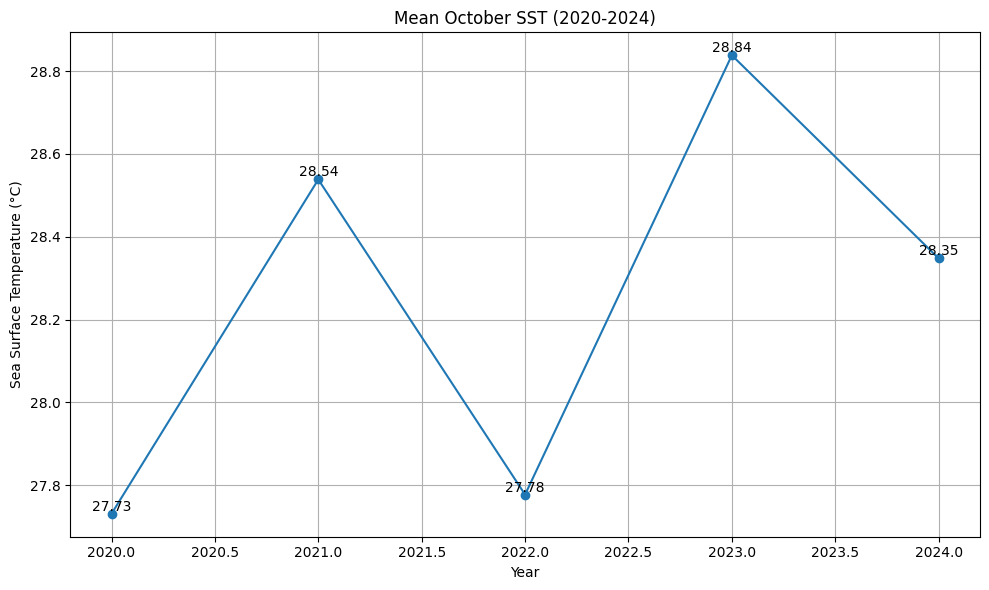

In [24]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

---

In [21]:
query = """Display a boxplot comparing the SST in the month of October \
over the years 2020-2024 in the region defined by the bounding box, \
"20N to 30N, -97W to -87W". \
Note that `plt.boxplot()` does not handle NaN values.
"""
print(query)
response = agent.run(query)

Display a boxplot comparing the SST in the month of October over the years 2020-2024 in the region defined by the bounding box, "20N to 30N, -97W to -87W". Note that `plt.boxplot()` does not handle NaN values.



2024-12-19 10:35:59 - e84_geoai_common.llm.models.claude - INFO - input_tokens=5258 output_tokens=612
2024-12-19 10:35:59 - e84_geoai_common.util - INFO - invoke_model_with_request took 75.050263 seconds to run.
2024-12-19 10:35:59 - e84_geoai_common.util - INFO - prompt took 75.050553 seconds to run.
2024-12-19 10:35:59 - llm_agent.agents.scientific_python_agent.scientific_python_agent - INFO - {
<thoughts>
To fulfill this request, we need to:
1. Filter the dataset for the specified region and time period.
2. Extract October data for each year from 2020 to 2024.
3. Remove NaN values from the data.
4. Create a boxplot comparing the SST distributions for each October.

We'll use the provided utility functions to filter the data and then process it to create the boxplot.
</thoughts>

<code>
```python
import matplotlib.pyplot as plt
import pandas as pd

# Filter the dataset for the specified region and time period
lat_range = slice(geographic_coords_to_decimal_coords("20N"), geographic_co

<string>:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.


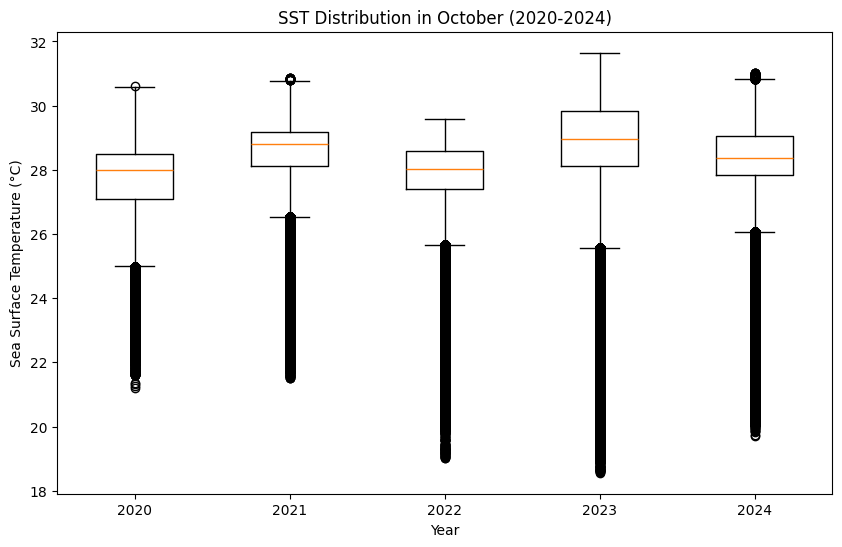

In [22]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

---

In [8]:
query = """What was the mean SST in the Black Sea on June 01, 2024?"""
print(query)
response = agent.run(query)

2024-12-19 16:07:40 - botocore.tokens - INFO - Loading cached SSO token for kmnlp


What was the mean SST in the Black Sea on June 01, 2024?


2024-12-19 16:07:51 - e84_geoai_common.llm.models.claude - INFO - input_tokens=5488 output_tokens=440
2024-12-19 16:07:51 - e84_geoai_common.util - INFO - invoke_model_with_request took 11.044764 seconds to run.
2024-12-19 16:07:51 - e84_geoai_common.util - INFO - prompt took 11.045084 seconds to run.
2024-12-19 16:07:51 - llm_agent.agents.scientific_python_agent.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to:
1. Filter the dataset to get the SST data for June 01, 2024.
2. Create a spatial mask for the Black Sea.
3. Apply the mask to the filtered SST data.
4. Calculate the mean of the resulting data.

We can use the provided utility functions to accomplish these tasks efficiently.
</thoughts>

<code>
```python
import numpy as np
from datetime import datetime

# 1. Filter the dataset for the specific date
date = "2024-06-01"
sst_data = filter_data_array(ds.analysed_sst, time=slice(date, date))

# 2. Create a spatial mask for the Black Sea
black_sea_polyg

In [9]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

/home/ahassan/mambaforge/envs/llm-agent/lib/python3.12/site-packages/distributed/client.py:3371: UserWarning: Sending large graph of size 24.80 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


The mean SST in the Black Sea on 2024-06-01 was 20.03 degrees Celsius.


---

In [11]:
query = """In the area within 5 miles of the coast of New Jersey, which days \
were the warmest and coldest, in terms of average SST, in June 2024?\
"""
print(query)
response = agent.run(query)

In the area within 5 miles of the coast of New Jersey, which days were the warmest and coldest, in terms of average SST, in June 2024?


2024-12-19 16:36:19 - e84_geoai_common.llm.models.claude - INFO - input_tokens=5507 output_tokens=693
2024-12-19 16:36:19 - e84_geoai_common.util - INFO - invoke_model_with_request took 13.987494 seconds to run.
2024-12-19 16:36:19 - e84_geoai_common.util - INFO - prompt took 13.987808 seconds to run.
2024-12-19 16:36:19 - llm_agent.agents.scientific_python_agent.scientific_python_agent - INFO - {
<thoughts>
To solve this problem, we need to follow these steps:
1. Define the area within 5 miles of the coast of New Jersey using the geocoding function.
2. Create a mask for this area using the polygon_to_mask function.
3. Filter the analysed_sst data for June 2024.
4. Apply the mask to the filtered data.
5. Calculate the daily average SST for the masked area.
6. Find the days with the maximum and minimum average SST.

This approach will allow us to identify the warmest and coldest days in the specified area during June 2024.
</thoughts>

<code>
```python
import numpy as np

# Step 1: Defi

In [12]:
try:
    exec(response.code)
except Exception:
    traceback.print_exc()

2024-12-19 16:36:20 - e84_geoai_common.llm.models.claude - INFO - input_tokens=2087 output_tokens=89
2024-12-19 16:36:20 - e84_geoai_common.util - INFO - invoke_model_with_request took 1.110677 seconds to run.
2024-12-19 16:36:20 - e84_geoai_common.util - INFO - prompt took 1.110902 seconds to run.


Searching for [New Jersey] geometry


2024-12-19 16:36:21 - e84_geoai_common.util - INFO - nominatim_search took 0.636554 seconds to run.
2024-12-19 16:36:21 - e84_geoai_common.util - INFO - simplify_geometry took 0.010266 seconds to run.


Nominatim place found for [New Jersey]: {"place_id": 330391211, "licence": "Data \u00a9 OpenStreetMap contributors, ODbL 1.0. http://osm.org


2024-12-19 16:36:22 - e84_geoai_common.util - INFO - coastline_of took 1.043704 seconds to run.
2024-12-19 16:36:22 - e84_geoai_common.util - INFO - simplify_geometry took 0.000059 seconds to run.
/home/ahassan/mambaforge/envs/llm-agent/lib/python3.12/site-packages/distributed/client.py:3371: UserWarning: Sending large graph of size 26.34 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(
/home/ahassan/mambaforge/envs/llm-agent/lib/python3.12/site-packages/distributed/client.py:3371: UserWarning: Sending large graph of size 26.34 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices

The warmest day was 2024-06-24T12:00:00.000000000 with an average SST of 24.35°C
The coldest day was 2024-06-01T12:00:00.000000000 with an average SST of 18.92°C


Verify geocoding and masking:

/home/ahassan/mambaforge/envs/llm-agent/lib/python3.12/site-packages/distributed/client.py:3371: UserWarning: Sending large graph of size 24.72 MiB.
This may cause some slowdown.
Consider loading the data with Dask directly
 or using futures or delayed objects to embed the data into the graph without repetition.
See also https://docs.dask.org/en/stable/best-practices.html#load-data-with-dask for more information.
  warnings.warn(


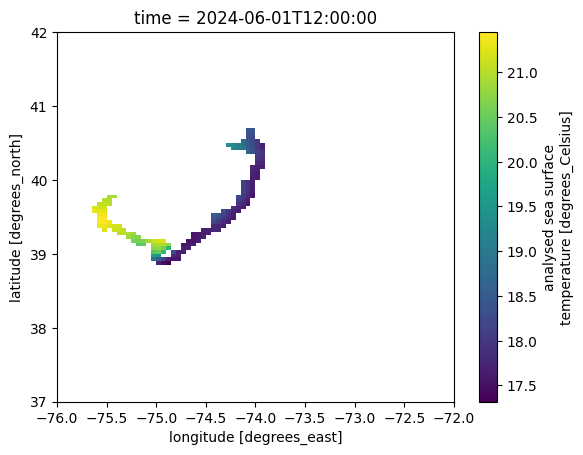

In [18]:
masked_data.sel(time='2024-06-01', lat=slice(37, 42), lon=slice(-76, -72)).plot()